In [1]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

print("Temporal Change Analysis")
print("Ready.")

Temporal Change Analysis
Ready.


In [2]:
from pathlib import Path
import rasterio
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    r"C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training"
)

SEP12 = PROJECT_DIR / "outputs/module_08_visualization/NISAR_LSAR_098_014_A_20260912/HHHH.tif"
OCT30 = PROJECT_DIR / "outputs/module_08_visualization/NISAR_LSAR_098_014_A_20261030/HHHH.tif"

print("12 Sep:", SEP12.exists())
print("30 Oct:", OCT30.exists())

12 Sep: True
30 Oct: True


In [3]:
def load_nisar_db(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float32)
        profile = src.profile.copy()

    data = np.where(data > 0, data, np.nan)

    # Convert linear power to dB
    db = 10 * np.log10(data)

    return db, profile


sep12_db, profile = load_nisar_db(SEP12)
oct30_db, _ = load_nisar_db(OCT30)

print("12 Sep shape:", sep12_db.shape)
print("30 Oct shape:", oct30_db.shape)

print("\n12 Sep mean:", np.nanmean(sep12_db))
print("30 Oct mean:", np.nanmean(oct30_db))

12 Sep shape: (2006, 2126)
30 Oct shape: (2006, 2126)

12 Sep mean: -11.954447
30 Oct mean: -10.341047


In [4]:
THRESHOLD_DB = -17

sep12_water = sep12_db < THRESHOLD_DB
oct30_water = oct30_db < THRESHOLD_DB

print("12 Sep water pixels:", np.sum(sep12_water))
print("30 Oct water pixels:", np.sum(oct30_water))

pixel_area_m2 = 10 * 10

sep12_area_km2 = np.sum(sep12_water) * pixel_area_m2 / 1_000_000
oct30_area_km2 = np.sum(oct30_water) * pixel_area_m2 / 1_000_000

print(f"\n12 Sep water area: {sep12_area_km2:.2f} km²")
print(f"30 Oct water area: {oct30_area_km2:.2f} km²")

12 Sep water pixels: 902845
30 Oct water pixels: 431898

12 Sep water area: 90.28 km²
30 Oct water area: 43.19 km²


In [5]:
# Temporal change classes
# 0 = no change
# 1 = water persisted
# 2 = water disappeared (12 Sep → 30 Oct)
# 3 = new water (30 Oct)

change_map = np.zeros(sep12_water.shape, dtype=np.uint8)

change_map[(sep12_water) & (oct30_water)] = 1
change_map[(sep12_water) & (~oct30_water)] = 2
change_map[(~sep12_water) & (oct30_water)] = 3

persistent_water = np.sum(change_map == 1)
water_receded = np.sum(change_map == 2)
new_water = np.sum(change_map == 3)

print("TEMPORAL CHANGE")
print("=" * 40)
print(f"Persistent water : {persistent_water:,} pixels")
print(f"Water disappeared: {water_receded:,} pixels")
print(f"New water        : {new_water:,} pixels")

print("\nWater disappeared area:",
      f"{water_receded * 100 / 1000000:.2f} km²")

print("New water area:",
      f"{new_water * 100 / 1000000:.2f} km²")

TEMPORAL CHANGE
Persistent water : 227,517 pixels
Water disappeared: 675,328 pixels
New water        : 204,381 pixels

Water disappeared area: 67.53 km²
New water area: 20.44 km²


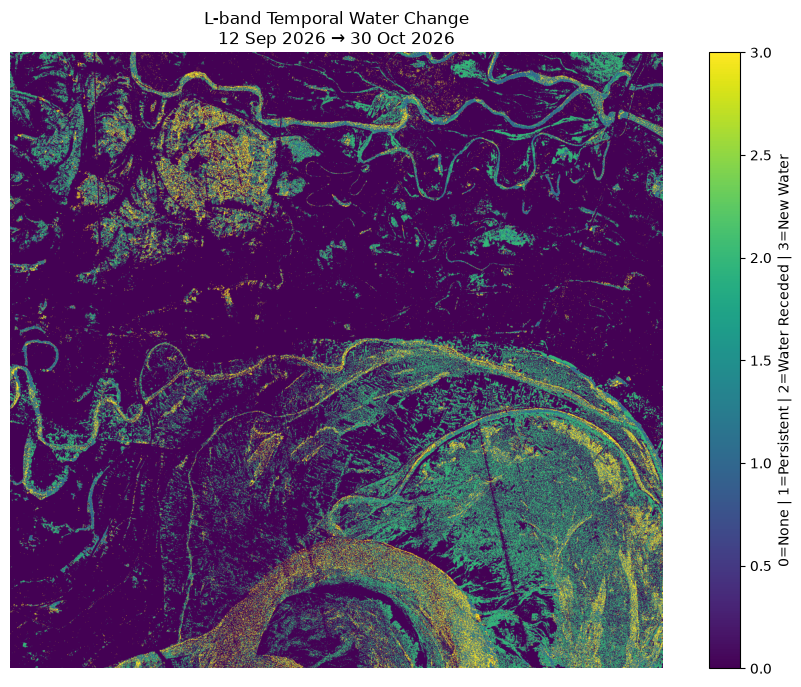

In [6]:
plt.figure(figsize=(12, 8))

plt.imshow(change_map, cmap="viridis")

plt.title(
    "L-band Temporal Water Change\n"
    "12 Sep 2026 → 30 Oct 2026"
)

plt.axis("off")
plt.colorbar(
    label="0=None | 1=Persistent | 2=Water Receded | 3=New Water"
)

plt.show()

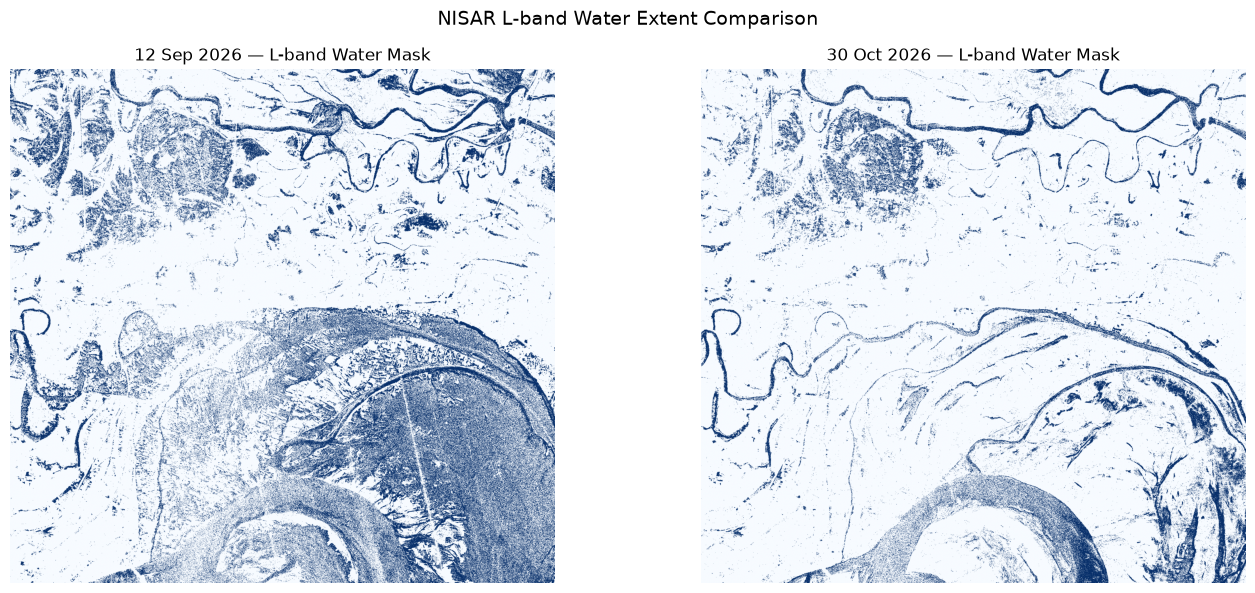

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(sep12_water, cmap="Blues")
axes[0].set_title("12 Sep 2026 — L-band Water Mask")
axes[0].axis("off")

axes[1].imshow(oct30_water, cmap="Blues")
axes[1].set_title("30 Oct 2026 — L-band Water Mask")
axes[1].axis("off")

plt.suptitle("NISAR L-band Water Extent Comparison", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path

S_FILES = sorted(
    PROJECT_DIR.glob(
        "outputs/**/NISAR_SSAR_*/HHHH.tif"
    )
)

print("=" * 60)
print("S-BAND HHHH FILES")
print("=" * 60)

for i, f in enumerate(S_FILES):
    print(f"{i}: {f}")

print("\nTotal S-band files:", len(S_FILES))

S-BAND HHHH FILES
0: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20260912\HHHH.tif
1: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif

Total S-band files: 2


In [9]:
# Get the two S-band HHHH files
S_FILES = sorted(S_FILES)

SEP12_S = S_FILES[0]
OCT30_S = S_FILES[1]

print("12 Sep S-band:", SEP12_S)
print("30 Oct S-band:", OCT30_S)

12 Sep S-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20260912\HHHH.tif
30 Oct S-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif


In [10]:
sep12_s_db, _ = load_nisar_db(SEP12_S)
oct30_s_db, _ = load_nisar_db(OCT30_S)

print("12 Sep S-band shape:", sep12_s_db.shape)
print("30 Oct S-band shape:", oct30_s_db.shape)

print("\n12 Sep S-band")
print("Min:", np.nanmin(sep12_s_db))
print("Max:", np.nanmax(sep12_s_db))
print("Mean:", np.nanmean(sep12_s_db))
print("Median:", np.nanmedian(sep12_s_db))

print("\n30 Oct S-band")
print("Min:", np.nanmin(oct30_s_db))
print("Max:", np.nanmax(oct30_s_db))
print("Mean:", np.nanmean(oct30_s_db))
print("Median:", np.nanmedian(oct30_s_db))

12 Sep S-band shape: (2006, 2126)
30 Oct S-band shape: (2006, 2126)

12 Sep S-band
Min: -31.893677
Max: 32.78386
Mean: -11.801535
Median: -11.3941765

30 Oct S-band
Min: -30.68681
Max: 29.308147
Mean: -9.83057
Median: -9.320839


In [11]:
print("=" * 60)
print("S-BAND WATER THRESHOLD TEST")
print("=" * 60)

for threshold in [-15, -16, -17, -18, -19, -20]:
    sep_pixels = np.sum(sep12_s_db < threshold)
    oct_pixels = np.sum(oct30_s_db < threshold)

    sep_percent = 100 * sep_pixels / np.sum(np.isfinite(sep12_s_db))
    oct_percent = 100 * oct_pixels / np.sum(np.isfinite(oct30_s_db))

    print(f"\nThreshold: {threshold} dB")
    print(f"12 Sep: {sep_pixels:,} pixels ({sep_percent:.2f}%)")
    print(f"30 Oct: {oct_pixels:,} pixels ({oct_percent:.2f}%)")

S-BAND WATER THRESHOLD TEST

Threshold: -15 dB
12 Sep: 1,337,437 pixels (31.36%)
30 Oct: 592,110 pixels (13.88%)

Threshold: -16 dB
12 Sep: 1,097,710 pixels (25.74%)
30 Oct: 443,969 pixels (10.41%)

Threshold: -17 dB
12 Sep: 853,617 pixels (20.02%)
30 Oct: 317,133 pixels (7.44%)

Threshold: -18 dB
12 Sep: 620,082 pixels (14.54%)
30 Oct: 213,371 pixels (5.00%)

Threshold: -19 dB
12 Sep: 418,173 pixels (9.81%)
30 Oct: 134,164 pixels (3.15%)

Threshold: -20 dB
12 Sep: 259,837 pixels (6.09%)
30 Oct: 78,292 pixels (1.84%)


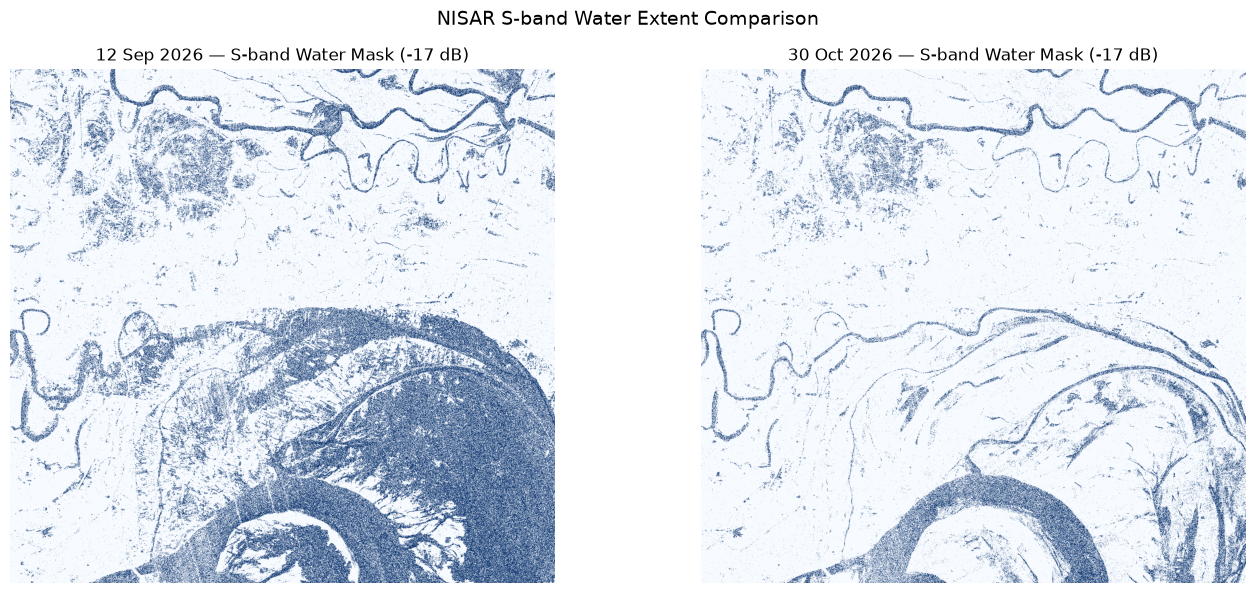

In [12]:
S_THRESHOLD = -17

sep12_s_water = sep12_s_db < S_THRESHOLD
oct30_s_water = oct30_s_db < S_THRESHOLD

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(sep12_s_water, cmap="Blues")
axes[0].set_title("12 Sep 2026 — S-band Water Mask (-17 dB)")
axes[0].axis("off")

axes[1].imshow(oct30_s_water, cmap="Blues")
axes[1].set_title("30 Oct 2026 — S-band Water Mask (-17 dB)")
axes[1].axis("off")

plt.suptitle("NISAR S-band Water Extent Comparison", fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# S-BAND TEMPORAL WATER CHANGE
# ============================================================

# 0 = No water
# 1 = Persistent water
# 2 = Water receded
# 3 = New water

s_temporal_change = np.zeros_like(sep12_s_water, dtype=np.uint8)

s_temporal_change[sep12_s_water & oct30_s_water] = 1
s_temporal_change[sep12_s_water & ~oct30_s_water] = 2
s_temporal_change[~sep12_s_water & oct30_s_water] = 3

# Statistics
total = np.sum(np.isfinite(sep12_s_db))

persistent = np.sum(s_temporal_change == 1)
receded = np.sum(s_temporal_change == 2)
new_water = np.sum(s_temporal_change == 3)

print("=" * 60)
print("S-BAND TEMPORAL WATER CHANGE")
print("=" * 60)

print(f"Persistent water: {persistent:,} pixels ({100*persistent/total:.2f}%)")
print(f"Receded water   : {receded:,} pixels ({100*receded/total:.2f}%)")
print(f"New water       : {new_water:,} pixels ({100*new_water/total:.2f}%)")

S-BAND TEMPORAL WATER CHANGE
Persistent water: 166,409 pixels (3.90%)
Receded water   : 687,208 pixels (16.11%)
New water       : 150,724 pixels (3.53%)


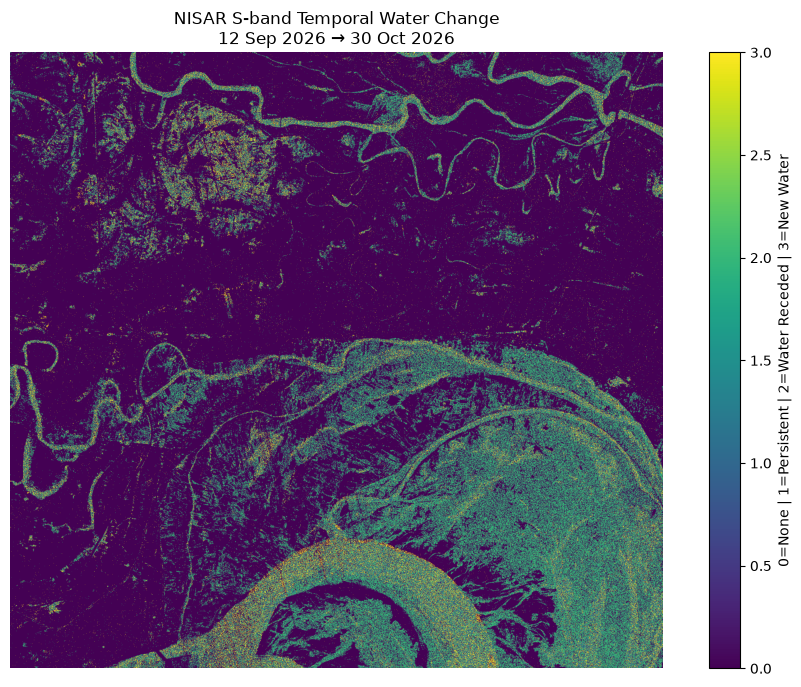

In [14]:
plt.figure(figsize=(12, 8))

plt.imshow(
    s_temporal_change,
    cmap="viridis",
    vmin=0,
    vmax=3
)

plt.title(
    "NISAR S-band Temporal Water Change\n"
    "12 Sep 2026 → 30 Oct 2026"
)

plt.axis("off")

plt.colorbar(
    label="0=None | 1=Persistent | 2=Water Receded | 3=New Water"
)

plt.show()